# GA1 — Data cleaning and exploratory analysis for booster uptake

Place this notebook and `COVID-19BehaviorData_CAN2022.csv` in the same folder when submitting. The code reads the CSV by a relative path and does not require a machine-specific location. In Google Colab, the runtime starts in a separate folder; if the CSV is absent, the first code cell prompts you to upload it to the runtime before continuing.

In [1]:
from pathlib import Path
import pandas as pd

input_path = Path("COVID-19BehaviorData_CAN2022.csv")

if not input_path.exists():
    try:
        from google.colab import files
    except ImportError as exc:
        raise FileNotFoundError(
            f"Put {input_path.name} in the same folder as this notebook, then run again."
        ) from exc
    print(f"Colab runtime cannot see {input_path.name}. Upload the CSV now.")
    uploaded = files.upload()
    if input_path.name not in uploaded:
        raise FileNotFoundError(f"Upload the file named {input_path.name} to continue.")

data = pd.read_csv(input_path, low_memory=False)
print(f"Original shape: {data.shape[0]:,} rows × {data.shape[1]:,} columns")

Original shape: 6,430 rows × 512 columns


## Standardize missing values and remove empty columns

The CSV uses whitespace and `__NA__` as missing-value markers. Convert both before checking whole columns. Keep partly observed columns for later predictor selection.

In [2]:
text_columns = data.select_dtypes(include=["object", "string"]).columns
data[text_columns] = data[text_columns].replace(r"^\s*$", pd.NA, regex=True)
data[text_columns] = data[text_columns].replace("__NA__", pd.NA)

empty_columns = data.columns[data.isna().all()].tolist()
cleaned_data = data.drop(columns=empty_columns)

print(f"Completely empty columns removed: {len(empty_columns):,}")
print(f"Cleaned shape: {cleaned_data.shape[0]:,} rows × {cleaned_data.shape[1]:,} columns")
print(f"First 15 removed columns: {empty_columns[:15]}")

Completely empty columns removed: 353
Cleaned shape: 6,430 rows × 159 columns
First 15 removed columns: ['i1_health', 'i7a_health', 'i3_health', 'i4_health', 'i5_health_1', 'i5_health_2', 'i5_health_3', 'i5_health_4', 'i5_health_5', 'i5_health_99', 'i5a_health', 'i6_health', 'i7b_health', 'i8_health', 'i10_health']


## Define `vac_boost_1` as the binary target

The booster question was skipped by all 644 respondents who reported receiving neither of the first two vaccine doses. For the objective **has received a booster / third dose**, infer `No` for these respondents. The untouched original survey responses remain in `cleaned_data`; the modeling copy fills `vac_boost_1` under this explicit assumption.

In [3]:
target = "vac_boost_1"

print("Original booster question responses:")
print(cleaned_data[target].value_counts(dropna=False).to_string())
print("\nOriginal vaccination status by booster response:")
print(pd.crosstab(cleaned_data["vac"], cleaned_data[target].fillna("Skipped")))

skipped = cleaned_data[target].isna()
assert skipped.sum() == 644
assert (cleaned_data.loc[skipped, "vac"] == "No, neither").all()
assert set(cleaned_data[target].dropna().unique()) == {"Yes", "No"}

model_cohort = cleaned_data.copy()
model_cohort[target] = model_cohort[target].fillna("No")
print(f"\nNo values inferred from documented skip: {skipped.sum():,}")
print(f"Model cohort: {len(model_cohort):,} rows × {model_cohort.shape[1]:,} columns")
print(model_cohort[target].value_counts().to_string())

Original booster question responses:
vac_boost_1
Yes     3646
No      2140
<NA>     644

Original vaccination status by booster response:
vac_boost_1       No  Skipped   Yes
vac                                
No, neither        0      644     0
Yes, one dose    167        0    60
Yes, two doses  1973        0  3586

No values inferred from documented skip: 644
Model cohort: 6,430 rows × 159 columns
vac_boost_1
Yes    3646
No     2784


## Remove columns with missing values

Review missingness in the full cohort, then remove every column that still has at least one missing value. No predictor subset is selected here. The filled target `vac_boost_1` remains.

In [4]:
missing_counts = model_cohort.isna().sum()
missing_summary = (
    pd.DataFrame({"missing_n": missing_counts, "missing_pct": missing_counts / len(model_cohort) * 100})
    .query("missing_n > 0")
    .sort_values("missing_pct", ascending=False)
)
missing_columns = missing_summary.index.tolist()
model_ready = model_cohort.drop(columns=missing_columns)

print(f"Columns removed for having missing values: {len(missing_columns):,}")
print(missing_summary.head(15).round(1).to_string())
print(f"\nComplete-column table shape: {model_ready.shape[0]:,} rows × {model_ready.shape[1]:,} columns")
assert target in model_ready
assert model_ready[target].notna().all()
assert not model_ready.isna().any().any()

Columns removed for having missing values: 101
                     missing_n  missing_pct
vac12_other               6348         98.7
Soc2_open                 6297         97.9
q_other                   6191         96.3
vac12_booster_other       6046         94.0
i14_health_other          5929         92.2
vac_1                     5786         90.0
vac12_7                   5786         90.0
vac12_1                   5786         90.0
vac12_2                   5786         90.0
vac12_3                   5786         90.0
vac12_4                   5786         90.0
vac12_11                  5786         90.0
vac12_5                   5786         90.0
vac12_6                   5786         90.0
vac12_8                   5786         90.0

Complete-column table shape: 6,430 rows × 58 columns


## Save cleaned data and complete-column table

The first CSV keeps all 159 nonempty original columns and the original target responses. The second CSV contains the complete-column table with the filled `vac_boost_1` target. No model or predictor subset has been chosen.

In [5]:
cleaned_path = Path("COVID-19BehaviorData_CAN2022_nonempty_columns.csv")
model_path = Path("COVID-19BehaviorData_CAN2022_booster_model_ready.csv")
cleaned_data.to_csv(cleaned_path, index=False)
model_ready.to_csv(model_path, index=False)

assert pd.read_csv(cleaned_path, low_memory=False).shape == cleaned_data.shape
assert pd.read_csv(model_path, low_memory=False).shape == model_ready.shape
assert model_ready[target].notna().all()
print(f"Saved {cleaned_path.name}: {cleaned_data.shape[0]:,} × {cleaned_data.shape[1]:,}")
print(f"Saved {model_path.name}: {model_ready.shape[0]:,} × {model_ready.shape[1]:,}")

Saved COVID-19BehaviorData_CAN2022_nonempty_columns.csv: 6,430 × 159
Saved COVID-19BehaviorData_CAN2022_booster_model_ready.csv: 6,430 × 58


## Exploratory data analysis (EDA)

**Question:** How does booster uptake vary across survey weeks, age groups, and vaccine attitudes? The figures use unweighted respondent percentages and describe associations only; they do not establish causal effects. The target counts the 644 skipped booster responses from people with no first or second dose as `No`.

In [6]:
import matplotlib.pyplot as plt

eda = model_ready.copy()
eda["booster_yes"] = eda["vac_boost_1"].eq("Yes")
print("Target distribution:")
print(eda["vac_boost_1"].value_counts().to_string())
print(f"Yes proportion: {eda['booster_yes'].mean():.1%}")

eda["age_group"] = pd.cut(
    eda["age"], bins=[17, 29, 39, 49, 59, 69, 120],
    labels=["18–29", "30–39", "40–49", "50–59", "60–69", "70+"]
)
week_order = [f"week {i}" for i in range(44, 51)]
trust_order = ["Not at all", "A little", "Moderately", "Very much"]
side_effect_order = ["1 - Strongly agree", "2", "3", "4", "5 – Strongly disagree"]

def uptake_table(group_col, order=None):
    result = eda.groupby(group_col, observed=True)["booster_yes"].agg(n="size", yes_rate="mean")
    return result.reindex(order) if order is not None else result

week_table = uptake_table("qweek", week_order)
age_table = uptake_table("age_group")
trust_table = uptake_table("vac7", trust_order)
side_effect_table = uptake_table("vac2_2", side_effect_order)
print("\nWeekly uptake (%):")
print((week_table.assign(yes_pct=lambda x: (x.yes_rate * 100).round(1))[["n", "yes_pct"]]).to_string())

Target distribution:
vac_boost_1
Yes    3646
No     2784
Yes proportion: 56.7%

Weekly uptake (%):
            n  yes_pct
qweek                 
week 44   627     30.6
week 45  1004     45.0
week 46   985     55.5
week 47   891     61.1
week 48   916     62.9
week 49  1006     65.1
week 50  1001     67.9


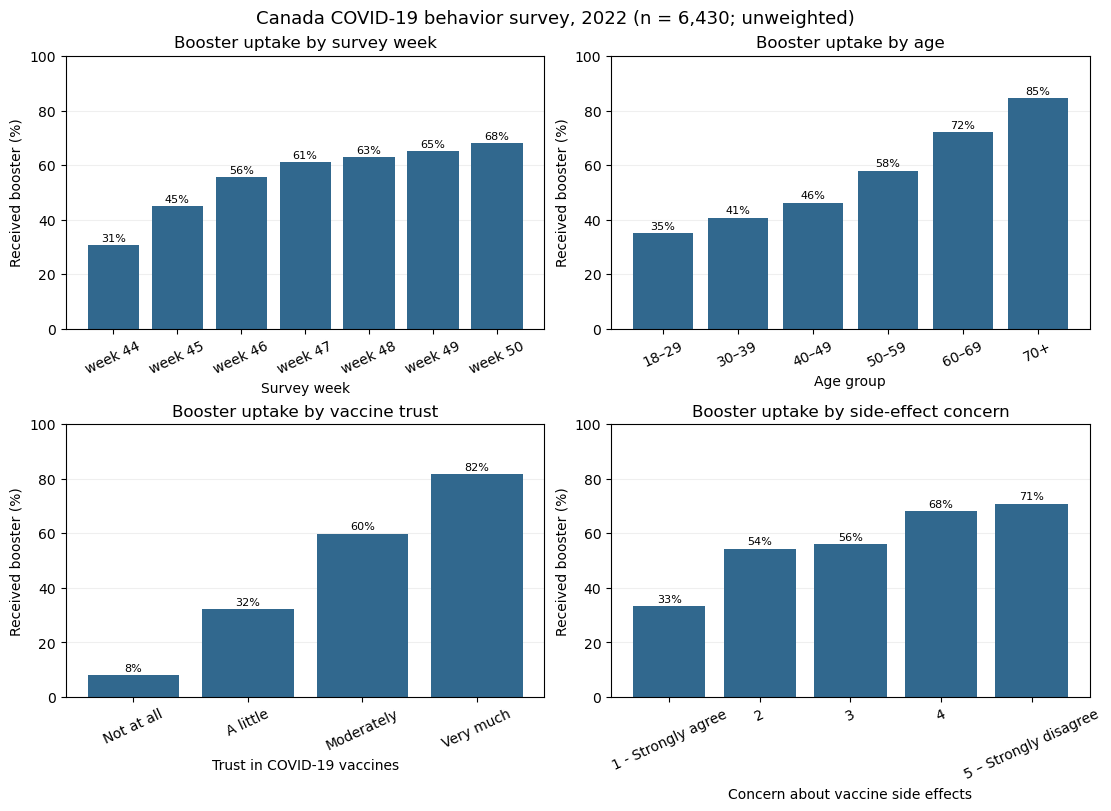

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8), constrained_layout=True)
plots = [
    (axes[0, 0], week_table, "Survey week", "Booster uptake by survey week"),
    (axes[0, 1], age_table, "Age group", "Booster uptake by age"),
    (axes[1, 0], trust_table, "Trust in COVID-19 vaccines", "Booster uptake by vaccine trust"),
    (axes[1, 1], side_effect_table, "Concern about vaccine side effects", "Booster uptake by side-effect concern"),
]
for ax, table, xlabel, title in plots:
    labels = table.index.astype(str)
    values = table.yes_rate * 100
    bars = ax.bar(labels, values, color="#31688e")
    ax.set(title=title, xlabel=xlabel, ylabel="Received booster (%)", ylim=(0, 100))
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", labelrotation=25)
    for bar, value in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width()/2, value + 1.5, f"{value:.0f}%", ha="center", fontsize=8)
fig.suptitle("Canada COVID-19 behavior survey, 2022 (n = 6,430; unweighted)", fontsize=13)
plt.show()

### EDA takeaways

- Booster uptake is **56.7%** overall (3,646 / 6,430).
- The unweighted share rises from **30.6% in week 44** to **67.9% in week 50**. Survey week is important context for other comparisons.
- Uptake rises from **35.1% among ages 18–29** to **84.6% among ages 70+**.
- Uptake ranges from **8.1%** among respondents who do not trust COVID-19 vaccines at all to **81.7%** among those who trust them very much. These are associations, not causal effects.
- The target includes 644 skipped responses inferred as No. No predictor set has been chosen.
- The data key includes some generic UK wording for Canadian fields; check wording before making institution-specific claims.

## Random train/test split and validation plan

Only the target is decided at this stage: `vac_boost_1`. Split the full cleaned 6,430 × 58 table 70%/30% by respondent, using a fixed seed and stratification to preserve the Yes/No balance. Within the 70% training portion, use stratified 5-fold cross-validation for later model selection: each fold trains on 4/5 and validates on 1/5 of the training portion. No predictor subset, encoding, scaling, or model is chosen here. Keep the 30% test set untouched until final evaluation.

In [8]:
from sklearn.model_selection import StratifiedKFold, train_test_split

SEED = 42

train_data, test_data = train_test_split(
    model_ready, test_size=0.30, random_state=SEED,
    stratify=model_ready["vac_boost_1"]
)
print(f"Training set: {train_data.shape[0]:,} rows × {train_data.shape[1]:,} columns")
print(f"Test set: {test_data.shape[0]:,} rows × {test_data.shape[1]:,} columns")
print("\nTraining target:")
print(train_data["vac_boost_1"].value_counts().to_string())
print("\nTest target:")
print(test_data["vac_boost_1"].value_counts().to_string())
assert len(train_data) + len(test_data) == len(model_ready)
assert set(train_data.index).isdisjoint(test_data.index)

validation_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
fold_sizes = [(len(train_idx), len(val_idx)) for train_idx, val_idx in validation_cv.split(train_data, train_data["vac_boost_1"])]
print(f"\nSeed: {SEED}; validation: stratified 5-fold CV within training set")
print(f"Train/validation rows per fold: {fold_sizes}")

Training set: 4,501 rows × 58 columns
Test set: 1,929 rows × 58 columns

Training target:
vac_boost_1
Yes    2552
No     1949

Test target:
vac_boost_1
Yes    1094
No      835

Seed: 42; validation: stratified 5-fold CV within training set
Train/validation rows per fold: [(3600, 901), (3601, 900), (3601, 900), (3601, 900), (3601, 900)]
